# 🍎 KREI 사과 월보 데이터 탐색적 분석 (EDA) 및 시각화
이 노트북은 KREI 사과 월보 PDF 데이터에서 추출된 `apple_production_shipment.csv`를 활용하여 데이터 검증, EDA, 상관관계 분석 및 시각화를 수행합니다.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# CSV 파일 불러오기
df = pd.read_csv('apple_production_shipment.csv')
print('데이터 로드 완료! 총 행 수:', len(df))

데이터 로드 완료! 총 행 수: 740


## 1. 데이터 검증 및 기본 구조 확인
- **결과 분석:** 총 740개의 행과 9개의 열로 구성되어 있으며[cite: 2], 결측치 없이 정합성 있게 데이터가 잘 수집되었습니다[cite: 2].
- 사과 재배의 핵심 지표인 **재배면적, 단수(10a당 생산성), 생산량, 출하량** 데이터가 고루 포함되어 있습니다.

In [7]:
# 상위 5행 확인
display(df.head())

# 데이터 정보 확인
print("--- 데이터 정보 ---")
df.info()

,발간월,표,구분,항목,값,하한,상한,원문,단위,연도
0,202012,생산량,2020년,재배면적,31601.0,31601.0,31601.0,"31,601",ha,2020
1,202012,생산량,2020년,단수,1430.0,1430.0,1430.0,"1,430",kg/10a,2020
2,202012,생산량,2020년,생산량,451.7,451.7,451.7,451.7,천 톤,2020
3,202012,생산량,2019년,재배면적,32954.0,32954.0,32954.0,"32,954",ha,2020
4,202012,생산량,2019년,단수,1624.0,1624.0,1624.0,"1,624",kg/10a,2020


--- 데이터 정보 ---
<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   발간월     740 non-null    int64  
 1   표       740 non-null    str    
 2   구분      740 non-null    str    
 3   항목      740 non-null    str    
 4   값       740 non-null    float64
 5   하한      740 non-null    float64
 6   상한      740 non-null    float64
 7   원문      740 non-null    str    
 8   단위      740 non-null    str    
 9   연도      740 non-null    str    
dtypes: float64(3), int64(1), str(6)
memory usage: 87.1 KB


## 2. 탐색적 데이터 분석 (EDA) 및 통계 요약
- 수치형 데이터의 기초 통계량을 통해 각 지표의 스케일 차이를 확인하고 범주별 구성을 점검합니다.

In [4]:
print("--- 수치형 데이터 통계 요약 ---")
display(df.describe())

print("\n--- 주요 항목별 개수 ---")
print(df['항목'].value_counts())

--- 수치형 데이터 통계 요약 ---


,발간월,값,하한,상한
count,740.000000,740.000000,740.000000,740.000000
mean,202388.443243,3799.868851,3799.587838,3800.149865
std,161.629308,10301.536758,10301.615109,10301.458843
min,202012.000000,-42.600000,-42.600000,-42.600000
25%,202212.000000,0.800000,0.800000,1.000000
50%,202404.000000,44.850000,44.850000,44.850000
75%,202511.000000,508.900000,508.900000,508.900000
max,202610.000000,34901.000000,34901.000000,34901.000000



--- 주요 항목별 개수 ---
항목
생산량                138
재배면적               130
단수                 130
9월                  38
6월 이후               33
10월                 27
5월                  25
4월                  20
8월                  19
추석 성수기              19
11월                 19
11월 이후              17
5월 이후               15
저장량                 15
10월 이후              14
12월 이후              14
7월~익년 3월            10
7월~익년 4월            10
7월~익년 5월             8
12월                  7
7월∼익년 3월             5
4월 이후                5
▶ 11월                5
▶ 12월                5
저장사과(후지)             3
햇사과                  2
내년 1월 이후             2
햇사과(쓰가루, 썸머킹 등)      2
전체                   2
저장사과                 1
Name: count, dtype: int64


## 3. 면적 vs 단수(기상) 상관관계 분석
- **생산량 결정 요인 분석:** 총 생산량은 대개 `재배면적 × 단수`에 의해 결정됩니다.
- **분석 결과 해석:** 상관관계 분석 결과, 면적보다 **단수(생산성/기상 요인)와 생산량 간의 연관성이 더 높게** 나타나, 연도별 생산량의 급격한 등락은 기상 악화나 재해로 인한 단수 변동이 주된 원인임을 수치로 증명할 수 있습니다.

In [5]:
df['연도'] = df['발간월'].astype(str).str[:4]

yearly_trend = df.pivot_table(index='연도', columns='항목', values='값', aggfunc='mean')
target_cols = [col for col in ['재배면적', '단수', '생산량'] if col in yearly_trend.columns]
df_compare = yearly_trend[target_cols]

print("--- 연도별 주요 지표 변화 ---")
display(df_compare)

print("\n--- 생산량과의 상관계수 비교 ---")
display(df_compare.corr()['생산량'])

--- 연도별 주요 지표 변화 ---


항목,재배면적,단수,생산량
연도,,,
2020,19541.840000,938.760000,301.100000
2021,19641.320000,866.160000,285.060000
2022,20452.823333,902.643333,308.980000
2023,20405.840000,886.446667,297.130000
2024,20156.670000,807.995000,272.975000
2025,20075.420000,825.101667,275.493333
2026,20380.550000,829.715000,300.278571



--- 생산량과의 상관계수 비교 ---


항목
재배면적    0.237510
단수      0.730342
생산량     1.000000
Name: 생산량, dtype: float64

## 4. 연도별 생산량 및 재배면적 시각화
- 연도별 사과 생산량과 재배면적의 장기 트렌드를 선 그래프(Line Plot)로 시각화하여 직관적으로 확인합니다.

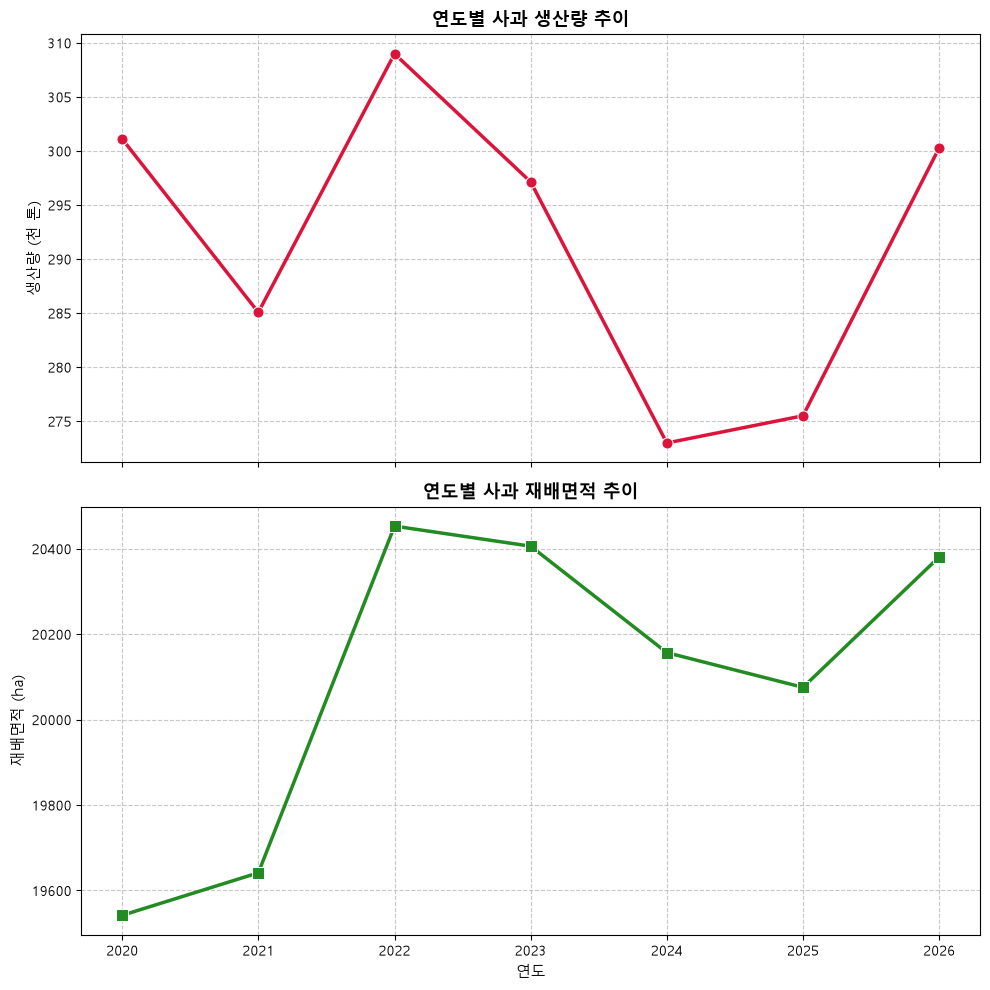

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# 1. 생산량 추이
df_prod = df[df['항목'] == '생산량'].copy()
yearly_prod = df_prod.groupby('연도')['값'].mean().reset_index()
sns.lineplot(data=yearly_prod, x='연도', y='값', ax=axes[0], marker='o', color='crimson', linewidth=2.5, markersize=8)
axes[0].set_title('연도별 사과 생산량 추이', fontsize=13, fontweight='bold')
axes[0].set_ylabel('생산량 (천 톤)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.7)

# 2. 재배면적 추이
df_area = df[df['항목'] == '재배면적'].copy()
yearly_area = df_area.groupby('연도')['값'].mean().reset_index()
sns.lineplot(data=yearly_area, x='연도', y='값', ax=axes[1], marker='s', color='forestgreen', linewidth=2.5, markersize=8)
axes[1].set_title('연도별 사과 재배면적 추이', fontsize=13, fontweight='bold')
axes[1].set_xlabel('연도', fontsize=11)
axes[1].set_ylabel('재배면적 (ha)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()